In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scipy

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

import pynapple as nap
from neo.rawio import BlackrockRawIO

from utils import load_session, load_task_events, label, split_by

In [2]:
# 20231104 is day 2 and consisted of short blocks (20 exposure blocks x 25 sequences)
# 20231105 is day 1 and consisted of long blocks (4 exposure blocks x 250 sequences)
# Both had 24% deviant rate during the training blocks, followed by a test phase of 10 exposure blocks x 25 sequences with 0% deviant rate

base_path = "../.."
derivatives_path = f"{base_path}/derivatives"
figure_path = f"{base_path}/figures"

day = "day1"
save_plots = False

if day == "day2":
    data_path = f"{base_path}/Recordings/Silas/Data/20231104"
    nev_a_path = f"{data_path}/SeqPre_110423_a001.nev"
    nev_p_path = f"{data_path}/SeqPre_110423_p001.nev"
    mat_path = f"{data_path}/Silas_231104_00_bhv.mat"
    n_exposure_blocks = 20
elif day == "day1":
    data_path = f"{base_path}/Recordings/Silas/Data/20231105"
    nev_a_path = f"{data_path}/SeqPres_231105_a001.nev"
    nev_p_path = f"{data_path}/SeqPres_231105_p001.nev"
    mat_path = f"{data_path}/Silas_231105_00_bhv.mat"
    n_exposure_blocks = 4
else:
    raise ValueError("invalid day")

In [3]:
# load_session: if cache_dir is provided and refresh=False, loads the data from cache
# if cache_dir is provided and refresh=True, loads data from scratch and overwrites the previously saved data
spikes_a, events_a, behav_a = load_session(nev_a_path, mat_path, cache_dir=f"{derivatives_path}/{day}", refresh=False)
# spikes_p, events_p, behav_p = load_session(nev_p_path)

In [4]:
imgs_a = events_a['images']
display(imgs_a[:5])

  index    start      end    image    block    seq    pos    code_onset  ...
      0  326.693  326.977        1        1      1      1        326.66  ...
      1  327.294  327.577        2        1      1      2        327.26  ...
      2  327.894  328.177        3        1      1      3        327.86  ...
      3  328.494  328.777        4        1      1      4        328.46  ...
      4  331.944  332.227        5        1      2      1        331.91  ...
shape: (5, 2), time unit: sec.

In [5]:
contexts = {
    "context1": lambda x: (x.block <= n_exposure_blocks) & (x.block % 2 == 1),
    "context2": lambda x: (x.block <= n_exposure_blocks) & (x.block % 2 == 0)
}

label(imgs_a, "context", contexts)  # label each image with a new column called "context" according to contexts (defined above)

index    start               end                 image    block    seq    pos    code_onset    context    ...
0        326.6931            326.97700000000003  1        1        1      1      326.66        context1   ...
1        327.2936            327.577             2        1        1      2      327.26        context1   ...
2        327.8936            328.177             3        1        1      3      327.86        context1   ...
3        328.4936            328.77700000000004  4        1        1      4      328.46        context1   ...
4        331.9436            332.2269            5        1        2      1      331.91        context1   ...
5        332.5435            332.8269            6        1        2      2      332.51        context1   ...
6        333.1435            333.4269            7        1        2      3      333.11        context1   ...
...      ...                 ...                 ...      ...      ...    ...    ...           ...        ...
4993     7

In [6]:
context_tuning = nap.compute_response_per_epoch(spikes_a, split_by(imgs_a, "context"))

In [7]:
cmap = plt.get_cmap('viridis')
colors = cmap(np.linspace(0.3,0.7,2))  # 2 contexts

In [8]:
def plot_mean_FR(context_tuning, figure_path, day, cmap):
    plt.scatter(context_tuning[:,0],context_tuning[:,1], color=cmap(0.5))
    plt.axline((0, 0), slope=1, color='black', linestyle='--', alpha=.3)
    plt.xlabel('Mean per-channel firing rate (Hz) for context 1')
    plt.ylabel('Mean per-channel firing rate (Hz) for context 2')
    plt.title(f'Mean firing rate for each channel on {day}')
    plt.savefig(f'{figure_path}/mean_contextdpdt_FR_{day}.png')
    plt.show()

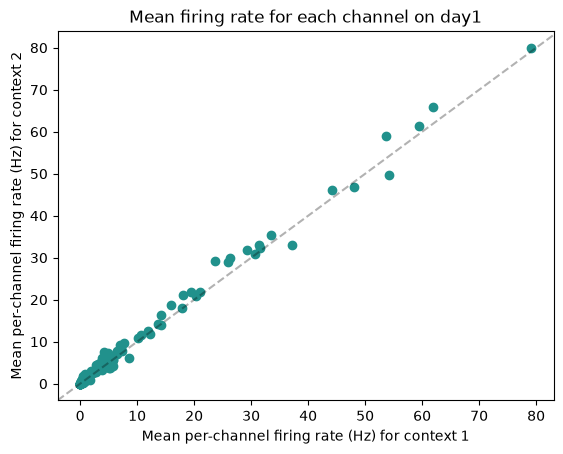

In [9]:
plot_mean_FR(context_tuning, figure_path, day, cmap)

In [10]:
bin_size = 0.02
window = (-0.2, 2.6)  # include data from 200ms before and after each sequence (4 images x 600ms = 2.4s per sequence)

In [11]:
# population PSTH around sequences, split by context
def plot_psth(imgs, spikes, colors, window, bin_size, day):
    first = imgs[imgs.pos == 1]
    counts = spikes.count(bin_size)
    
    fig, ax = plt.subplots(figsize=(9, 4))
    
    for i, ctx in enumerate(["context1", "context2"]):
        onsets = nap.Ts(t=first[first.context == ctx].start)
        p = nap.compute_perievent(counts, onsets, window=window)    # (time, sequences, channels)
        rate = np.nanmean(np.asarray(p), axis=2) / bin_size         # population rate per sequence (Hz)
        m = rate.mean(axis=1)
        sem = rate.std(axis=1) / np.sqrt(rate.shape[1])
        ax.plot(p.t, m, label=ctx, color=colors[i])
        ax.fill_between(p.t, m - sem, m + sem, alpha=0.2, color=colors[i])
    
    # shade each image's on-screen period (photodiode times, median relative to image 1)
    for k in range(1, 5):
        on = np.median(imgs[imgs.pos == k].start - first.start)
        off = np.median(imgs[imgs.pos == k].end - first.start)
        ax.axvspan(on, off, color="0.9", zorder=0)
        ax.text((on + off) / 2, 1.0, f"image {k}", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom")
    
    ax.set(xlabel="time from image 1 onset (s)", ylabel="firing rate (Hz)", xlim=window)
    ax.legend(frameon=False)
    plt.title(f'Mean population firing rate on {day}', pad=20)
    plt.tight_layout()
    plt.savefig(f'{figure_path}/population_contextdpdt_FR_{day}')
    plt.show()

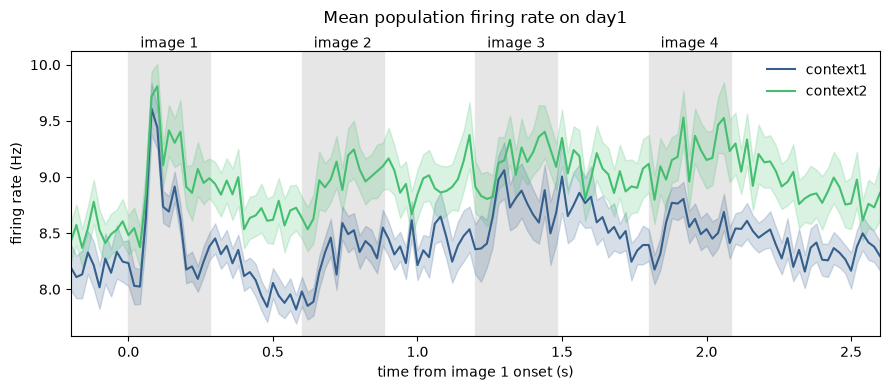

In [12]:
plot_psth(imgs_a, spikes_a, colors, window, bin_size, day)

In [13]:
def plot_psth_channels(contexts, spikes, window, bin_size, imgs, colors, day):
    first = imgs[imgs.pos == 1]
    counts = spikes.count(bin_size)
    
    # rate[ctx]: (time, sequences, channels), in Hz — computed once, reused by every subplot
    rate = {}
    for ctx in contexts:
        p = nap.compute_perievent(counts, nap.Ts(t=first[first.context == ctx].start), window=window)
        rate[ctx] = np.asarray(p) / bin_size
    t = p.t
    
    img_on = [np.median(imgs[imgs.pos == k].start - first.start) for k in range(1, 5)]
    img_off = [np.median(imgs[imgs.pos == k].end - first.start) for k in range(1, 5)]
    ch_ids = np.asarray(spikes.channel_id)
    
    fig, axs = plt.subplots(16, 8, figsize=(16, 28), sharex=True, constrained_layout=True)
    for ch, ax in enumerate(axs.flat):
        for on, off in zip(img_on, img_off):
            ax.axvspan(on, off, color="0.9", zorder=0)
        for i, ctx in enumerate(contexts):
            r = rate[ctx][:, :, ch]
            m, sem = r.mean(axis=1), r.std(axis=1) / np.sqrt(r.shape[1])
            ax.plot(t, m, lw=0.8, label=ctx, color=colors[i])
            ax.fill_between(t, m - sem, m + sem, alpha=0.2, lw=0, color=colors[i])
        ax.set_title(f"ch {ch_ids[ch]}", fontsize=7, pad=2)
        ax.tick_params(labelsize=6)
    
    axs[0, 0].legend(fontsize=6, frameon=False)
    for ax in axs[-1]:
        ax.set_xticks(img_on, [f"img {k}" for k in range(1, 5)])
    fig.supxlabel("time (s) in trial, aligned to image 1 onset")
    fig.supylabel("firing rate (Hz)")
    fig.suptitle('Per-channel PSTH split by contexts')
    plt.savefig(f'{figure_path}/perchannel_contextdpdt_FR_{day}')
    plt.show()

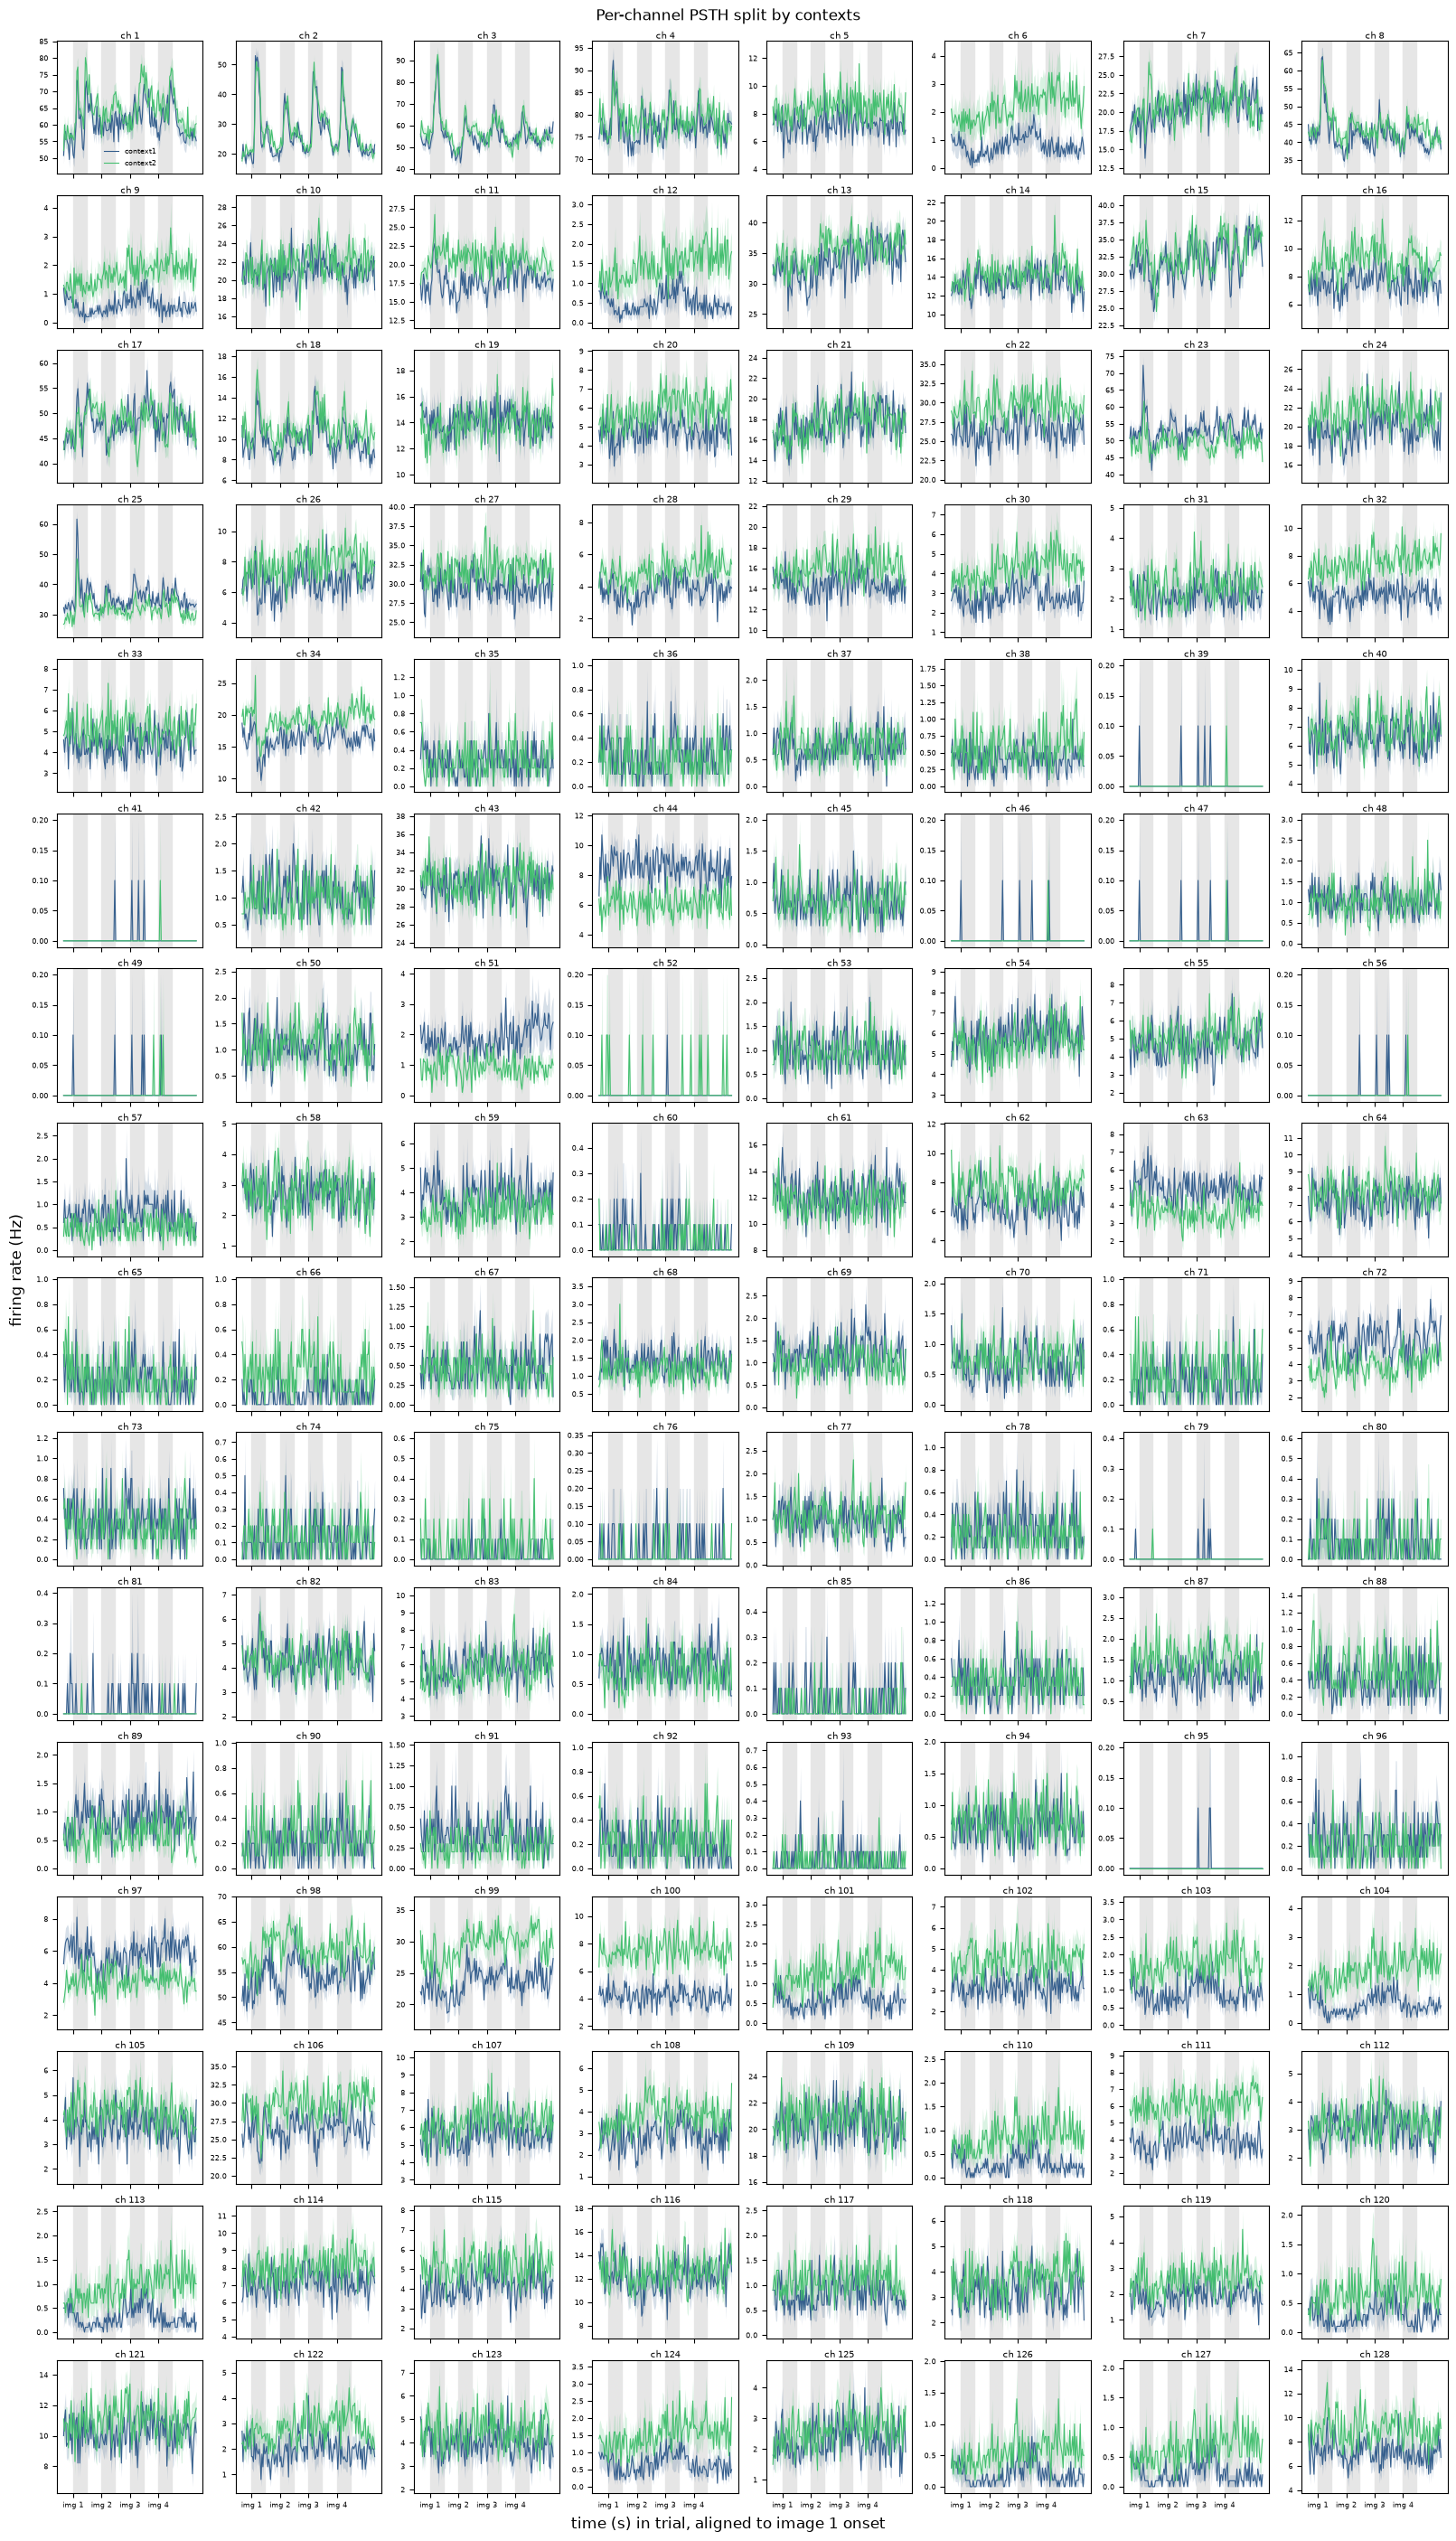

In [14]:
plot_psth_channels(contexts, spikes_a, window, bin_size, imgs_a, colors, day)

In [15]:
def get_first_half_mask(iset):
    # True for stimuli that occur in the first half of blocks in the provided IntervalSet
    half_idx = len(np.unique(iset.block.values)) // 2
    return iset['block'] <= half_idx

In [16]:
# context decoding PSTH
# cross-validate 50/50 based on first-half/second-half of blocks per condition with 2 folds to account for drift-over-time and adjacent-trials-in-train-and-test confound
# train: spike count per channel per trial

exposure_imgs_a = imgs_a[imgs_a['context'] != 'none']
seqs = exposure_imgs_a[exposure_imgs_a.pos == 1]           # one row per sequence (its first image)
first_half_mask = get_first_half_mask(seqs).to_numpy()
classes = seqs.context.to_numpy()

pre, post, bs = 0.2, 2.6, 0.05                             # post = end of window rel. to sequence onset
assert np.isclose((pre + post) / bs, round((pre + post) / bs))
win = nap.IntervalSet(start=seqs.start - pre, end=seqs.start + post)
assert np.all(win.start[1:] > win.end[:-1])

exposure_counts_a = nap.build_tensor(spikes_a, win, bin_size=bs)
exposure_counts_a = np.transpose(exposure_counts_a, (1,2,0))
assert exposure_counts_a.shape[0] == len(classes) and not np.isnan(exposure_counts_a).any()
n_bins = exposure_counts_a.shape[1]
print(exposure_counts_a.shape)

assert len(set(classes)) == 2  # should only be 2 classes (context1 and context2)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))  # by default L2 regularized

folds = [(first_half_mask, ~first_half_mask), (~first_half_mask, first_half_mask)]  # train/test on half 1/2 on fold 1, then swap for fold 2
acc = np.zeros((n_bins, 2))
pred = np.empty(shape=(exposure_counts_a.shape[0], n_bins), dtype=object)
for b in range(n_bins):
    X_b = exposure_counts_a[:, b, :]
    for i, (train, test) in enumerate(folds):
        model = clf.fit(X_b[train], classes[train])
        pred[test, b] = model.predict(X_b[test])
        acc[b, i] = balanced_accuracy_score(classes[test], pred[test, b])

(1000, 56, 128)


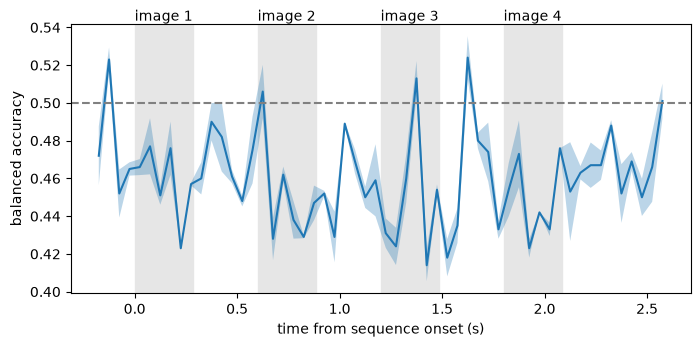

In [17]:
t = -pre + bs * (np.arange(n_bins) + 0.5)
fig, ax = plt.subplots(figsize=(8, 3.5))
for k in range(1, 5):
    pos_k = exposure_imgs_a[exposure_imgs_a.pos == k]
    assert len(pos_k) == len(seqs)                         # every sequence has image k
    on, off = np.median(pos_k.start - seqs.start), np.median(pos_k.end - seqs.start)
    ax.axvspan(on, off, color="0.9", zorder=0)
    ax.text((on + off) / 2, 1.0, f"image {k}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom")
m, sem = acc.mean(axis=1), acc.std(axis=1) / np.sqrt(acc.shape[1])
ax.plot(t, m)
ax.fill_between(t, m - sem, m + sem, alpha=0.3, lw=0)
ax.axhline(0.5, ls="--", c="gray")
ax.set(xlabel="time from sequence onset (s)", ylabel="balanced accuracy")
plt.show()